# Benchmark results: polity accuracy
Cultura life-stage polities compared with the polities read from historians' biographies (`03_cliopatria_association.ipynb`).

In [1]:
import json
import sys
from pathlib import Path

import polars as pl

ROOT = Path.cwd().resolve()
while not (ROOT / ".git").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "notebooks" / "notebooks_analysis"))
from style import show_table

FOLDER = ROOT / "scripts" / "5-annotations" / "benchmark" / "benchmark300"
STAGES_EXPORT = ROOT / "data" / "enriched_parquets" / "individual_life_stage_polities"
CLIOPATRIA = ROOT / "data" / "cliopatria_data" / "cliopatria_V2" / "cliopatria_polities_only_v3.geojson"
STAGES = {"pre_active": "Pre-active life", "active": "Active life", "post_active": "Post-active life"}

people = pl.DataFrame([{"qid": person["qid"], "region": person["claude_estimated_region"], "birth_year": person["cultura_birth_date_year"], "notability": person["notability"]}
                       for person in json.loads((FOLDER / "benchmark300_texts.json").read_text(encoding="utf-8"))])
benchmark = pl.read_parquet(FOLDER / "benchmark_life_stage_polities.parquet").select("qid", "stage", "polities", "candidate_polities")
cultura = (pl.scan_parquet(STAGES_EXPORT / "batch_*.parquet").filter(pl.col("qid").is_in(benchmark["qid"].unique().implode()))
           .select("qid", "stage", pl.col("polities").alias("cultura_polities")).collect())

parents = {}
for feature in json.loads(CLIOPATRIA.read_text())["features"]:
    polity = feature["properties"]
    for parent in filter(None, polity["MemberOf"].split(";")):
        parents.setdefault(polity["Name"].strip("()"), set()).add(parent.strip("()"))
    for child in filter(None, polity["Components"].split(";")):
        parents.setdefault(child.strip("()"), set()).add(polity["Name"].strip("()"))


def ancestors(name):
    found, todo = set(), [name]
    while todo:
        for parent in parents.get(todo.pop(), ()):
            if parent not in found:
                found.add(parent)
                todo.append(parent)
    return found


def related(found, given):
    return found == given or given in ancestors(found) or found in ancestors(given)


def validated(row):
    """A Cultura polity is a benchmark polity or one of the stage's Cliopatria candidates, directly or through a parent polity."""
    return any(related(found, given) for found in row["polities"] + row["candidate_polities"] for given in row["cultura_polities"])


both = benchmark.join(cultura, on=["qid", "stage"], how="full", coalesce=True).with_columns(pl.col("polities", "candidate_polities", "cultura_polities").fill_null([]))
print(both.group_by("stage").agg(benchmark=(pl.col("candidate_polities").list.len() > 0).sum(), cultura=(pl.col("cultura_polities").list.len() > 0).sum(),
                                 both=((pl.col("candidate_polities").list.len() > 0) & (pl.col("cultura_polities").list.len() > 0)).sum()))
compared = (both.filter((pl.col("candidate_polities").list.len() > 0) & (pl.col("cultura_polities").list.len() > 0))
            .with_columns(validated=pl.struct("polities", "candidate_polities", "cultura_polities").map_elements(validated, return_dtype=pl.Boolean))
            .join(people, on="qid")
            .with_columns(century=pl.col("birth_year") // 100 + 1))
print(f"{compared['qid'].n_unique()} individuals, {len(compared)} stages compared")


def accuracy(frame, by, label):
    return (frame.group_by(by).agg(Individuals=pl.col("qid").n_unique(), Compared=pl.len(), Validated=pl.col("validated").sum())
            .select(by, "Individuals", **{"Accuracy (%)": (100 * pl.col("Validated") / pl.col("Compared")).round(1)})
            .rename({by: label}))


def century_name(century):
    number = abs(century) if century > 0 else abs(century) + 1
    suffix = "th" if 10 <= number % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(number % 10, "th")
    return f"{number}{suffix} c." + (" BCE" if century <= 0 else "")


def by_group(column, label):
    """Individuals, accuracy per stage and overall for each value of column."""
    per_stage = (compared.group_by(column, "stage").agg(accuracy=(100 * pl.col("validated").mean()).round(1))
                 .pivot(on="stage", index=column, values="accuracy")
                 .select(column, *[pl.col(stage).alias(f"{name} (%)") for stage, name in STAGES.items()]))
    return (accuracy(compared, column, column).join(per_stage, on=column)
            .select(pl.col(column).alias(label), "Individuals", *[f"{name} (%)" for name in STAGES.values()], pl.col("Accuracy (%)").alias("Overall (%)")))

shape: (3, 4)
┌─────────────┬───────────┬─────────┬──────┐
│ stage       ┆ benchmark ┆ cultura ┆ both │
│ ---         ┆ ---       ┆ ---     ┆ ---  │
│ str         ┆ u32       ┆ u32     ┆ u32  │
╞═════════════╪═══════════╪═════════╪══════╡
│ active      ┆ 496       ┆ 531     ┆ 486  │
│ pre_active  ┆ 397       ┆ 532     ┆ 391  │
│ post_active ┆ 346       ┆ 358     ┆ 236  │
└─────────────┴───────────┴─────────┴──────┘
513 individuals, 1113 stages compared


## Table 14: Agreement per life stage

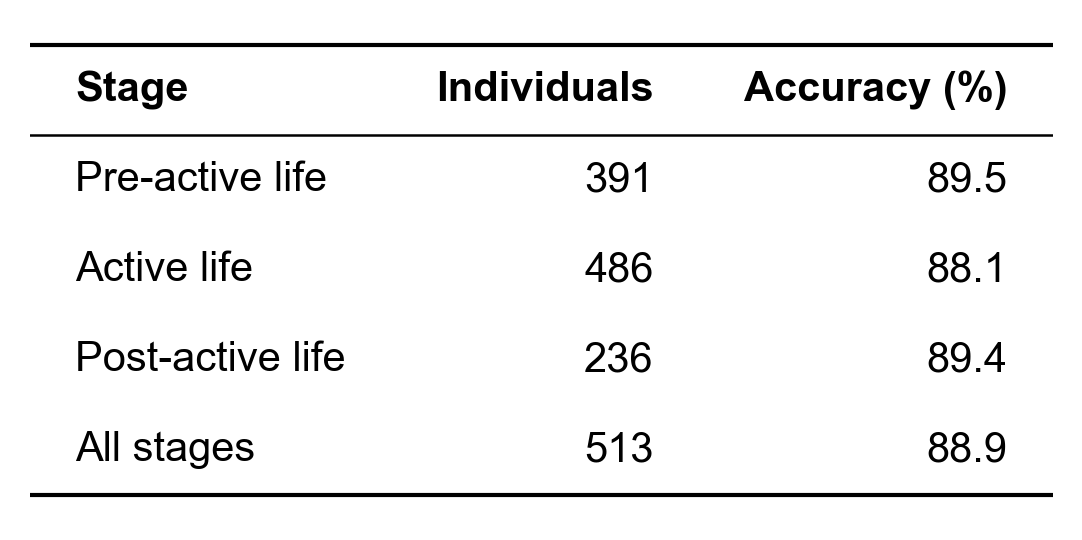

In [2]:
by_stage = accuracy(compared, "stage", "Stage").sort(pl.col("Stage").cast(pl.Enum(list(STAGES)))).with_columns(pl.col("Stage").replace(STAGES))
overall = accuracy(compared.with_columns(stage=pl.lit("All stages")), "stage", "Stage")
show_table(pl.concat([by_stage, overall]), decimals=1, font_size=10)

## Table 15: Agreement per region and life stage

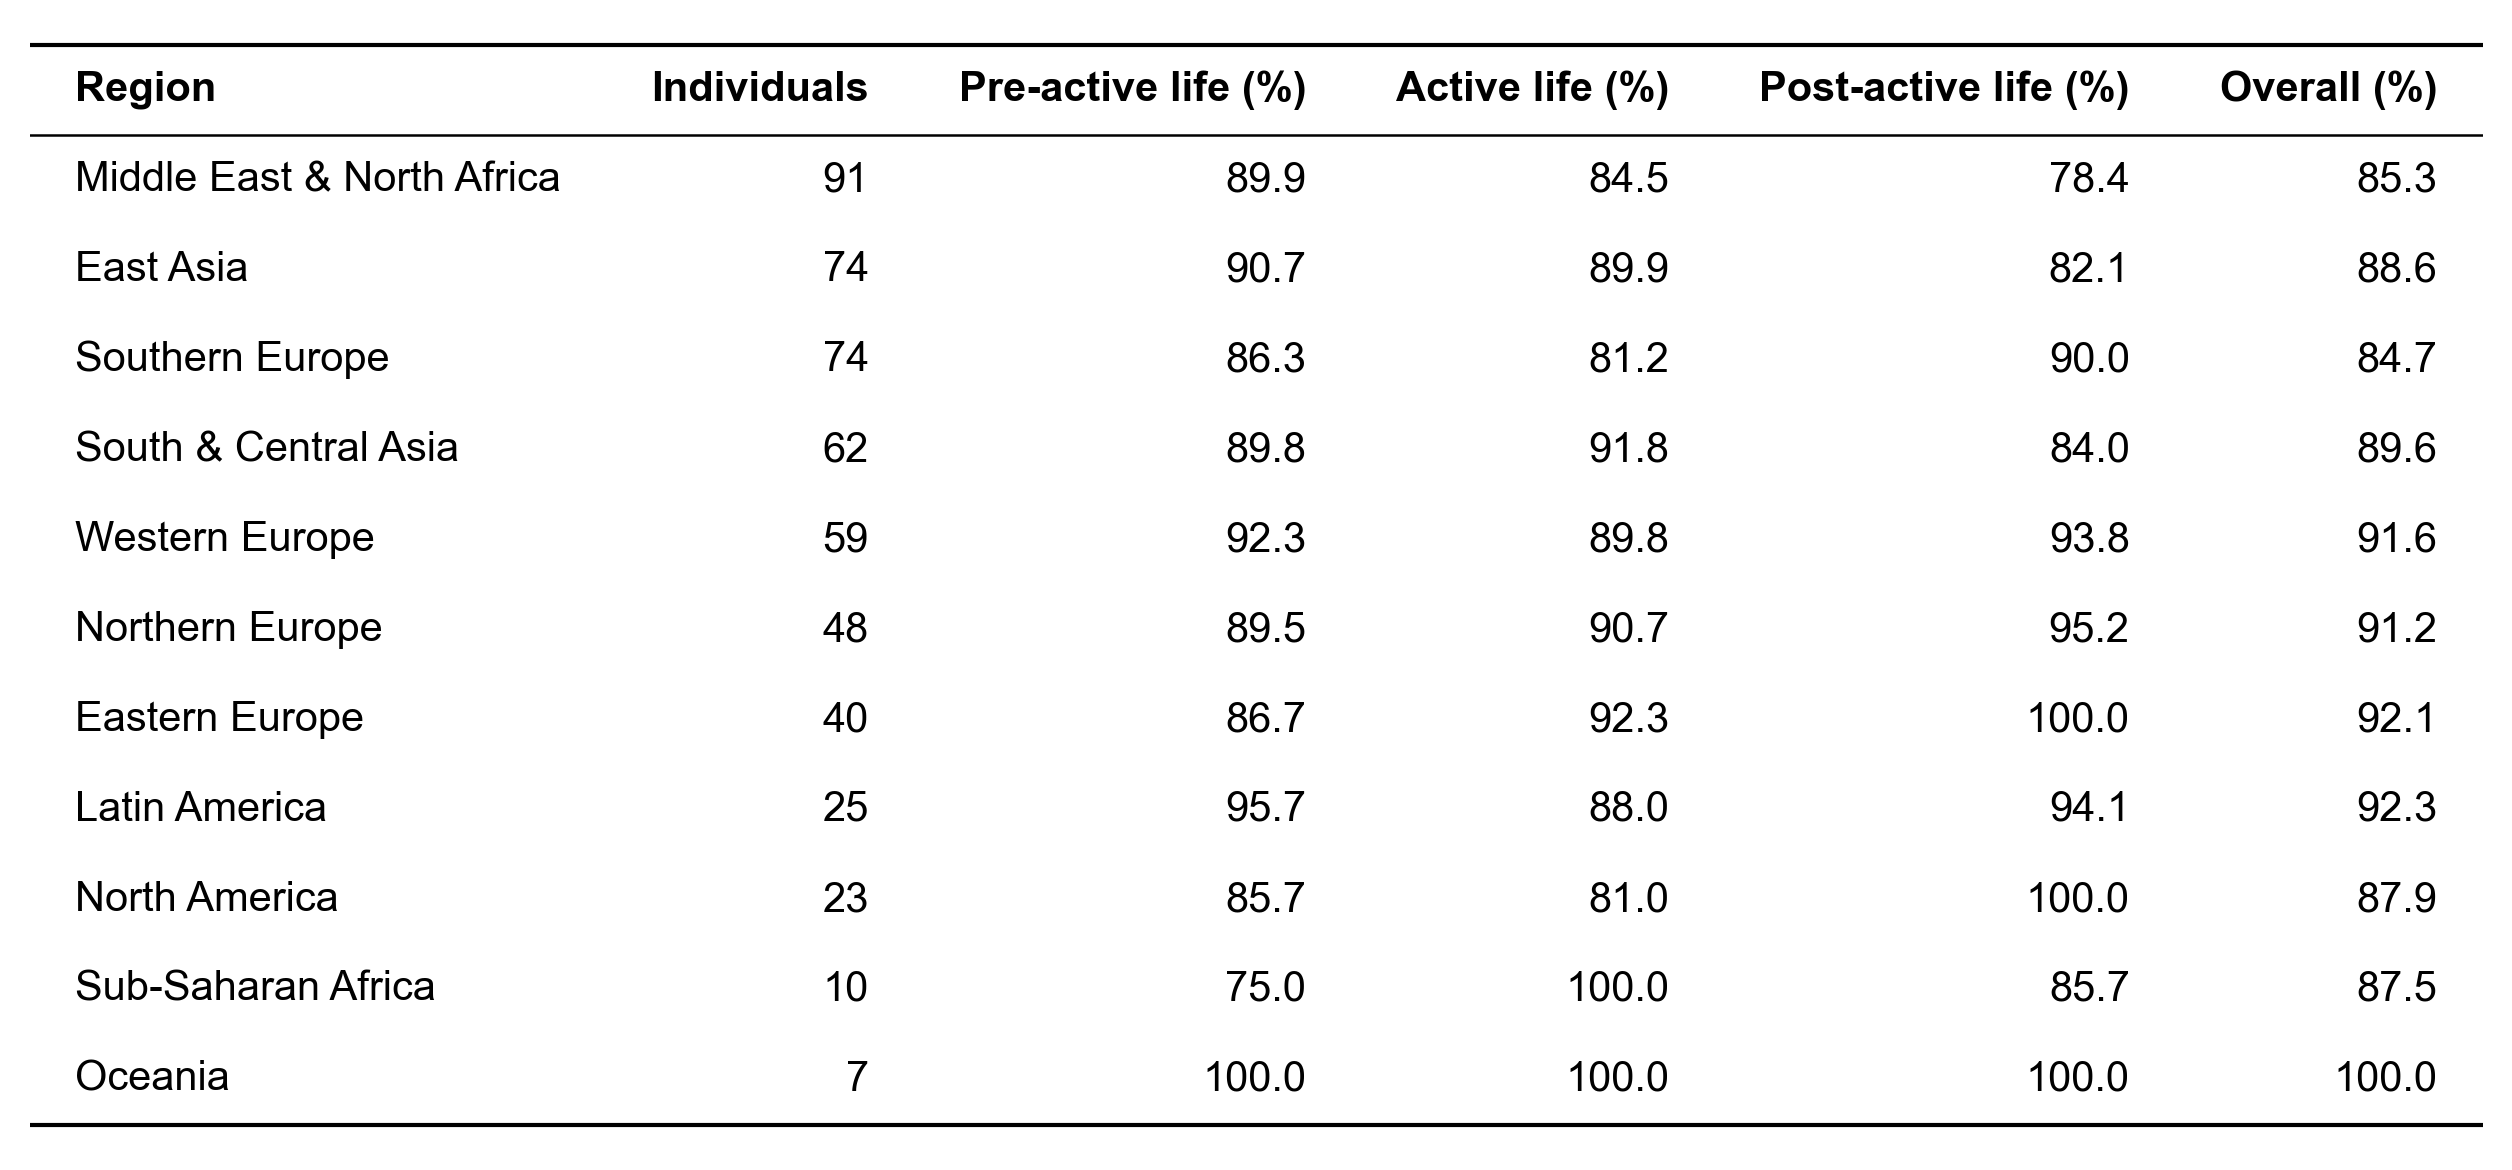

In [5]:
show_table(by_group("region", "Region").sort("Individuals", "Region", descending=[True, False]), decimals=1, font_size=10)

## Figure S2: Agreement per region and century of birth

In [ ]:
grid = (compared.group_by("region", "century").agg(Individuals=pl.col("qid").n_unique(), accuracy=(100 * pl.col("validated").mean()).round(1))
        .sort("century"))
centuries = grid["century"].unique().sort().to_list()
region_order = by_group("region", "Region").sort("Individuals", "Region", descending=[True, False])["Region"].to_list()

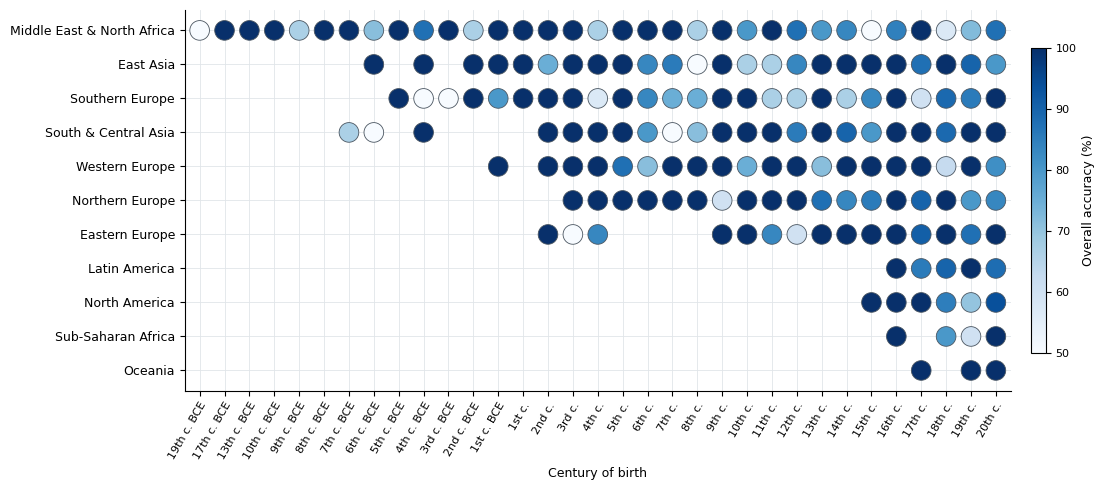

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

points = grid.with_columns(x=pl.col("century").replace_strict({century: i for i, century in enumerate(centuries)}),
                           y=pl.col("region").replace_strict({region: i for i, region in enumerate(region_order)}))
norm = Normalize(vmin=50, vmax=100)
fig, ax = plt.subplots(figsize=(12, 5))
dots = ax.scatter(points["x"], points["y"], s=200, c=points["accuracy"], cmap="Blues", norm=norm,
                  edgecolors="#4a5560", linewidths=0.6, zorder=3)
ax.set_xticks(range(len(centuries)), [century_name(century) for century in centuries], fontsize=8, rotation=60, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(region_order)), region_order, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-0.6, len(centuries) - 0.4)
ax.set_ylim(len(region_order) - 0.4, -0.6)
ax.grid(color="#e1e5e9", linewidth=0.6, zorder=0)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_xlabel("Century of birth", fontsize=9)
colorbar = fig.colorbar(dots, ax=ax, pad=0.02, shrink=0.8)
colorbar.set_label("Overall accuracy (%)", fontsize=9)
colorbar.ax.tick_params(labelsize=8)
fig.tight_layout()
plt.show()